# 06 · Training with histogram matching (`hist_split`)

Same model and training settings as `04_baseline`. **One change:** every EuroSAT image is first
corrected with `hist_split` from `05_preprocessing` (separate histogram matching for land and
water images), so the training images look like the Level-2A test images.
The Kaggle test images are not changed.

| | Baseline (04) | This run |
|---|---|---|
| Correction of training images | none | `hist_split` |
| Everything else | EfficientNet-B0, 12 bands, rotations/flips, same hyperparameters | same |
| Kaggle public score | 56.48% | see section 8 |

Run outputs go to `runs/<date>_hist_split_effb0/` (weights, config, history, metrics, `submission.csv`).

**Train or load.** With `LOAD_RUN` set (section 1), the notebook skips training, loads the saved
weights of that run and recomputes every result from them. Set `LOAD_RUN = None` to train a new model.

## 1 · Setup

In [1]:
import sys
from dataclasses import asdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import classification_report, confusion_matrix

sys.path.insert(0, str(Path.cwd().parent))
from src.data import CLASSES, PROJECT_ROOT, TEST_BANDS, band_index, load_split, load_test, load_train
from src.preprocessing import load_matcher
from src.models import MEDIUM_TRACK_LIMIT, build_model
from src.plot_style import SPLIT_COLORS, TEST_COLOR, TRAIN_COLOR, MUTED, apply_style
from src.training import (Normalizer, TrainConfig, fit, load_run, new_run_dir, predict_proba,
                          save_run, to_device_images, write_submission)
from src.utils import count_parameters, describe_device, get_device, seed_everything

apply_style()

RUN_NAME = "hist_split_effb0"
LOAD_RUN = "runs/2026-10-12_0910_hist_split_effb0"   # None = train a new model
PREPROCESS = "hist_split"     # matcher saved by 05_preprocessing.ipynb
SEED = 42
MODEL = "efficientnet_b0"
BANDS = TEST_BANDS                 # all 12 bands
cfg = TrainConfig(epochs=20, batch_size=128, lr=1e-3, weight_decay=1e-4,
                  label_smoothing=0.1, patience=5, augment=True)

seed_everything(SEED)
device = get_device()              # CUDA > Apple GPU (MPS) > CPU
print("Device:", describe_device(device))

Device: Apple GPU (MPS)


## 2 · Data

Images come from the cache built by `src/data.py`, the split from `03_split.ipynb`.
All EuroSAT images (train, val, internal test) are corrected with the saved `hist_split` matcher.
It was fitted on the training split and the unlabelled Kaggle images only, so validation and
internal test stay untouched by the fit. The normalisation statistics are then computed on the
corrected **training split only**.

In [2]:
X_all, meta = load_train()
X_kaggle, test_ids = load_test()
split = load_split()
band_idx = [band_index(b) for b in BANDS]

matcher = load_matcher(PROJECT_ROOT / "artifacts" / "preprocessing" / f"{PREPROCESS}.json")

def subset(name):
    rows = np.flatnonzero(split["split"].values == name)
    corrected = matcher(np.asarray(X_all[rows]))          # correction works on all 12 bands
    return corrected[:, band_idx], split["label_id"].values[rows]

X_tr, y_tr = subset("train")
X_va, y_va = subset("val")
X_te, y_te = subset("test")
X_kg = np.asarray(X_kaggle[:, band_idx])

normalizer = Normalizer.fit(X_tr)

# Move everything to the GPU once (int16, about 3 GB in total)
tr_images, tr_labels = to_device_images(X_tr, device), torch.from_numpy(y_tr).to(device)
va_images, va_labels = to_device_images(X_va, device), torch.from_numpy(y_va).to(device)
te_images = to_device_images(X_te, device)
kg_images = to_device_images(X_kg, device)

print(f"train {len(X_tr):,}  val {len(X_va):,}  internal test {len(X_te):,}  Kaggle test {len(X_kg):,}")
pd.DataFrame({"mean": normalizer.mean, "std": normalizer.std}, index=BANDS).round(1).T

train 18,900  val 4,050  internal test 4,050  Kaggle test 4,232


,B01,B02,B03,B04,B05,B06,B07,B08,B8A,B09,B11,B12
mean,399.3,429.6,696.0,641.2,1075.5,2135.8,2483.6,2590.3,2678.7,2667.6,1733.6,1107.9
std,310.3,410.6,483.3,613.2,614.1,1032.3,1257.1,1346.0,1339.6,1271.9,993.9,814.5


## 3 · Model

In [3]:
if LOAD_RUN:
    model, normalizer, saved_config = load_run(PROJECT_ROOT / LOAD_RUN, device)
    print(f"Loaded weights from {LOAD_RUN}")
else:
    model = build_model(MODEL, bands=list(BANDS), pretrained=True).to(device)
n_params = count_parameters(model)
assert n_params <= MEDIUM_TRACK_LIMIT, "too many parameters for the medium track"
print(f"{MODEL}: {n_params:,} parameters (medium track limit {MEDIUM_TRACK_LIMIT:,})")

Loaded weights from runs/2026-10-12_0910_hist_split_effb0
efficientnet_b0: 4,022,950 parameters (medium track limit 10,000,000)


## 4 · Training

After every epoch the model also predicts the **unlabelled Kaggle test set**, to watch the domain
shift without spending submissions:

- `kg_conf`: mean confidence on Kaggle test images (compare with `val_conf`). A large gap means the model is unsure on the shifted data.
- `kg_sealake`: share of Kaggle images predicted as SeaLake. The EDA suggests about 20–25%.

In [4]:
def monitor(m):
    val_p = predict_proba(m, va_images, normalizer)
    kg_p = predict_proba(m, kg_images, normalizer)
    return {
        "val_conf": float(val_p.max(1).mean()),
        "kg_conf": float(kg_p.max(1).mean()),
        "kg_sealake": float((kg_p.argmax(1) == CLASSES.index("SeaLake")).mean()),
        **{f"kg_share_{c}": float((kg_p.argmax(1) == i).mean()) for i, c in enumerate(CLASSES)},
    }

if LOAD_RUN:
    history = pd.read_csv(PROJECT_ROOT / LOAD_RUN / "history.csv")
    print(f"Training skipped: loaded the training history of {LOAD_RUN} ({len(history)} epochs)")
else:
    history, best_state = fit(model, tr_images, tr_labels, va_images, va_labels, normalizer, cfg, monitor=monitor)

Training skipped: loaded the training history of runs/2026-10-12_0910_hist_split_effb0 (20 epochs)


## 5 · Training curves

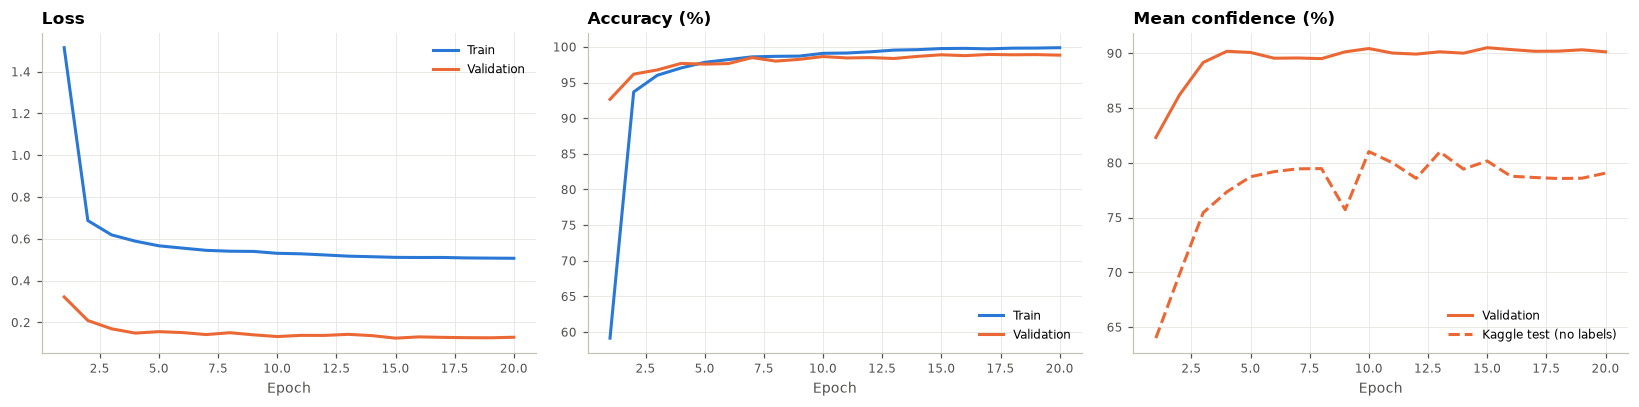

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
e = history["epoch"]

ax = axes[0]
ax.plot(e, history["train_loss"], color=TRAIN_COLOR, label="Train")
ax.plot(e, history["val_loss"], color=SPLIT_COLORS["val"], label="Validation")
ax.set_title("Loss", loc="left"); ax.set_xlabel("Epoch"); ax.legend()

ax = axes[1]
ax.plot(e, history["train_acc"] * 100, color=TRAIN_COLOR, label="Train")
ax.plot(e, history["val_acc"] * 100, color=SPLIT_COLORS["val"], label="Validation")
ax.set_title("Accuracy (%)", loc="left"); ax.set_xlabel("Epoch"); ax.legend()

ax = axes[2]
ax.plot(e, history["val_conf"] * 100, color=SPLIT_COLORS["val"], label="Validation")
ax.plot(e, history["kg_conf"] * 100, color=TEST_COLOR, ls="--", label="Kaggle test (no labels)")
ax.set_title("Mean confidence (%)", loc="left"); ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout()
plt.show()

## 6 · Internal test set

Measured once, on the best epoch. This shows how well the model learned EuroSAT itself.
It says nothing about the Level-2A test set.

In [6]:
te_prob = predict_proba(model, te_images, normalizer)
te_pred = te_prob.argmax(1)
test_acc = float((te_pred == y_te).mean())
val_acc = float(history["val_acc"].max())
print(f"Validation accuracy (best epoch): {val_acc:.2%}")
print(f"Internal test accuracy:           {test_acc:.2%}\n")
print(classification_report(y_te, te_pred, target_names=CLASSES, digits=3))

Validation accuracy (best epoch): 98.94%
Internal test accuracy:           98.64%

                      precision    recall  f1-score   support

          AnnualCrop      0.989     0.976     0.982       450
              Forest      0.996     0.996     0.996       450
HerbaceousVegetation      0.980     0.976     0.978       450
             Highway      0.979     0.979     0.979       375
          Industrial      0.992     0.987     0.989       375
             Pasture      0.973     0.973     0.973       300
       PermanentCrop      0.974     0.984     0.979       375
         Residential      0.993     0.996     0.994       450
               River      0.982     0.995     0.988       375
             SeaLake      1.000     1.000     1.000       450

            accuracy                          0.986      4050
           macro avg      0.986     0.986     0.986      4050
        weighted avg      0.986     0.986     0.986      4050



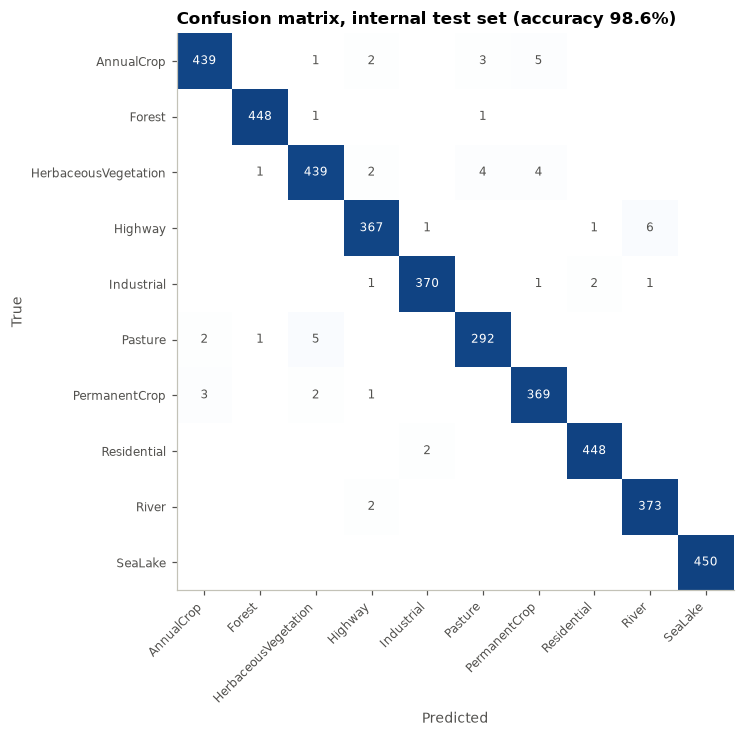

In [7]:
cm = confusion_matrix(y_te, te_pred)
cm_share = cm / cm.sum(axis=1, keepdims=True)
blues = LinearSegmentedColormap.from_list("blues", ["#ffffff", "#86b6ef", "#2a78d6", "#104281"])

fig, ax = plt.subplots(figsize=(8, 6.8))
ax.imshow(cm_share, cmap=blues, vmin=0, vmax=1)
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                    color="white" if cm_share[i, j] > 0.5 else "#52514e")
ax.set_xticks(range(10), CLASSES, rotation=45, ha="right")
ax.set_yticks(range(10), CLASSES)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title(f"Confusion matrix, internal test set (accuracy {test_acc:.1%})", loc="left")
ax.grid(False)
plt.tight_layout()
plt.show()

## 7 · Kaggle predictions

The Kaggle images are used as they are (no correction) and normalised with the training
statistics, exactly like submission A of the baseline. Test-time augmentation averages
the 8 rotations/flips of each image.

In [8]:
kg_prob = predict_proba(model, kg_images, normalizer, tta=True)
kg_conf = float(kg_prob.max(1).mean())

mix = pd.DataFrame({
    "this run": np.bincount(kg_prob.argmax(1), minlength=10) / len(kg_prob) * 100,
    "train split": np.bincount(y_tr, minlength=10) / len(y_tr) * 100,
}, index=CLASSES)
print(f"Mean confidence on Kaggle images: {kg_conf:.1%}")
mix.round(1).rename(columns=lambda c: c + " (%)")

Mean confidence on Kaggle images: 75.1%


,this run (%),train split (%)
AnnualCrop,2.4,11.1
Forest,11.5,11.1
HerbaceousVegetation,5.6,11.1
Highway,11.4,9.3
Industrial,6.3,9.3
Pasture,6.9,7.4
PermanentCrop,18.7,9.3
Residential,6.7,11.1
River,6.3,9.3
SeaLake,24.3,11.1


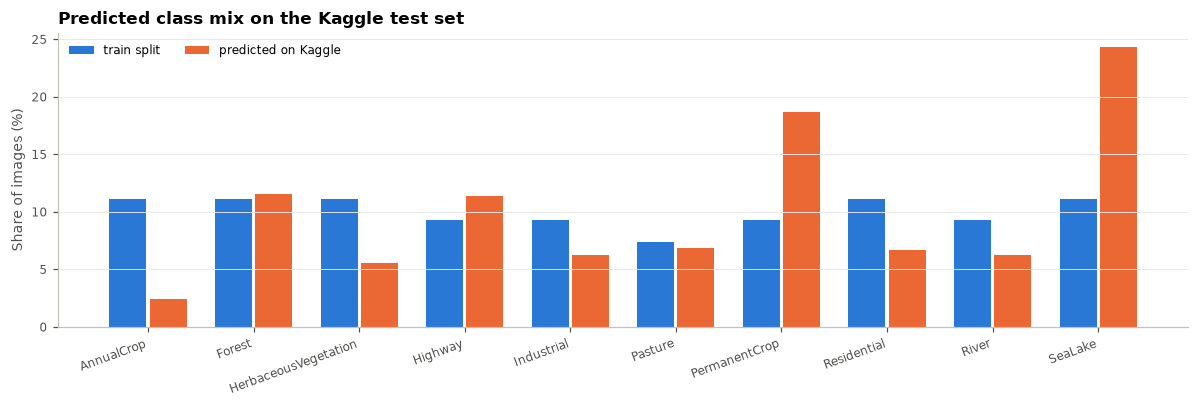

In [9]:
fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(10)
w = 0.38
ax.bar(x - w / 2, mix["train split"], w - 0.03, color=TRAIN_COLOR, label="train split")
ax.bar(x + w / 2, mix["this run"], w - 0.03, color=TEST_COLOR, label="predicted on Kaggle")
ax.set_xticks(x, CLASSES, rotation=20, ha="right")
ax.set_ylabel("Share of images (%)")
ax.set_title("Predicted class mix on the Kaggle test set", loc="left")
ax.grid(axis="x", visible=False)
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

## 8 · Save the run

In [10]:
if LOAD_RUN:
    run_dir = PROJECT_ROOT / LOAD_RUN
else:
    run_dir = new_run_dir(RUN_NAME)
    config = {
        "run_name": RUN_NAME, "model": MODEL, "bands": list(BANDS), "seed": SEED,
        "n_params": n_params, "device": describe_device(device),
        "normalizer": asdict(normalizer), "preprocess": PREPROCESS,
        "train": asdict(cfg), "split": "split_seed42",
    }
    metrics = {
        "val_acc": val_acc, "internal_test_acc": test_acc,
        "best_epoch": int(history.loc[history["val_acc"].idxmax(), "epoch"]),
        "kaggle_mean_confidence": kg_conf,
        "kaggle_predicted_mix_pct": mix["this run"].round(2).to_dict(),
        "kaggle_public_score": None,  # fill in after submitting
    }
    save_run(run_dir, best_state, config, history, metrics)

write_submission(kg_prob, test_ids, run_dir / "submission.csv")

print("Run folder:", run_dir.relative_to(PROJECT_ROOT))
for f in sorted(run_dir.iterdir()):
    print(f"  {f.name:20} {f.stat().st_size / 1e6:6.2f} MB")

Run folder: runs/2026-10-12_0910_hist_split_effb0
  config.json            0.00 MB
  history.csv            0.01 MB
  metrics.json           0.00 MB
  model.pt              16.35 MB
  submission.csv         0.06 MB


## 9 · Next steps

1. Submitted: **64.06%** public score (baseline 56.48%), so the correction is worth about +7.6 points.
2. Compare with the baseline (56.48%). `05_preprocessing` showed that contrast within images
   still differs, so the next single changes are per-image contrast augmentation, per-image
   normalisation and dropping B01/B09.